# Ekman flux form: cancellation of h ∇⋅M and the flux divergence

Why `ekman_plots.ipynb` uses the advection form $-M \cdot \nabla h$: in the flux form $-\nabla\cdot(M h)$, the large $h \nabla\cdot M$ (h measured from 0 K) nearly cancels. Same libraries (`composites.jl`, `maps.jl`), period and region as `ekman_plots.ipynb`.

Kernel: the Jupyter kernel "Julia" (IJulia), which shows each figure at the end of its cell.

In [1]:
using Revise, Dates
includet("composites.jl") # reading composites, computing fields
includet("maps.jl")       # plotting

# display settings, which depend on the platform; change them here if figures look wrong or hang
plot_defaults!(; dpi=100) # inline figure size on screen (inches x dpi); fonts=[...]: font list
PythonPlot.svg(false)     # true: inline SVG, which scales to the pane (maps are rasterized, so it stays small)

false

## Data
The period (May), region and `Ro_rad`, as in `ekman_plots.ipynb`; see there.

In [2]:
file = "../ekman_pentad_clim_2012-2020.nc"
lonlim, latlim = (40, 110), (0, 25) # degrees: Indian Ocean; only this region is read
Ro_rad = 250e3 # m, curtail M by r = 1 - exp(-y^2/Ro_rad^2) near the equator (plotting only)
figtitle(f) = "$(basename(file)): $(period_label(f.dimval)) (Ro_rad = $(Ro_rad/1e3) km)"

# May: the 6 pentads best aligned with May (year ignored): pentads 25:30, May 1-30
f = ekman_fields(file, Date(2001, 5, 1), Date(2001, 5, 31); n=6, lonlim, latlim, Ro_rad)
f.dimval, size(f.Mx), keys(f)

(Int32[25, 26, 27, 28, 29, 30], (281, 101), (:lon, :lat, :taux, :tauy, :Mx, :My, :m_a, :m_o, :dmodx, :dmody, :dmadx, :dmady, :advT_o, :advT_a, :adv_o, :adv_a, :sdiv_o, :sdiv_a, :flux_o, :flux_a, :r, :land, :dim, :dimval))

## Cancellation of Ekman divergence and flux divergence tendency
So use advection form.

Columns: ocean, atmosphere. The flux form $-\nabla\cdot(M h)$ is from the saved composites of $s\tau_x$, $s\tau_y$; $h \nabla\cdot M = $ adv $-$ flux. h is measured from 0 K, so $h \nabla\cdot M$ is large and nearly cancels in the flux form.

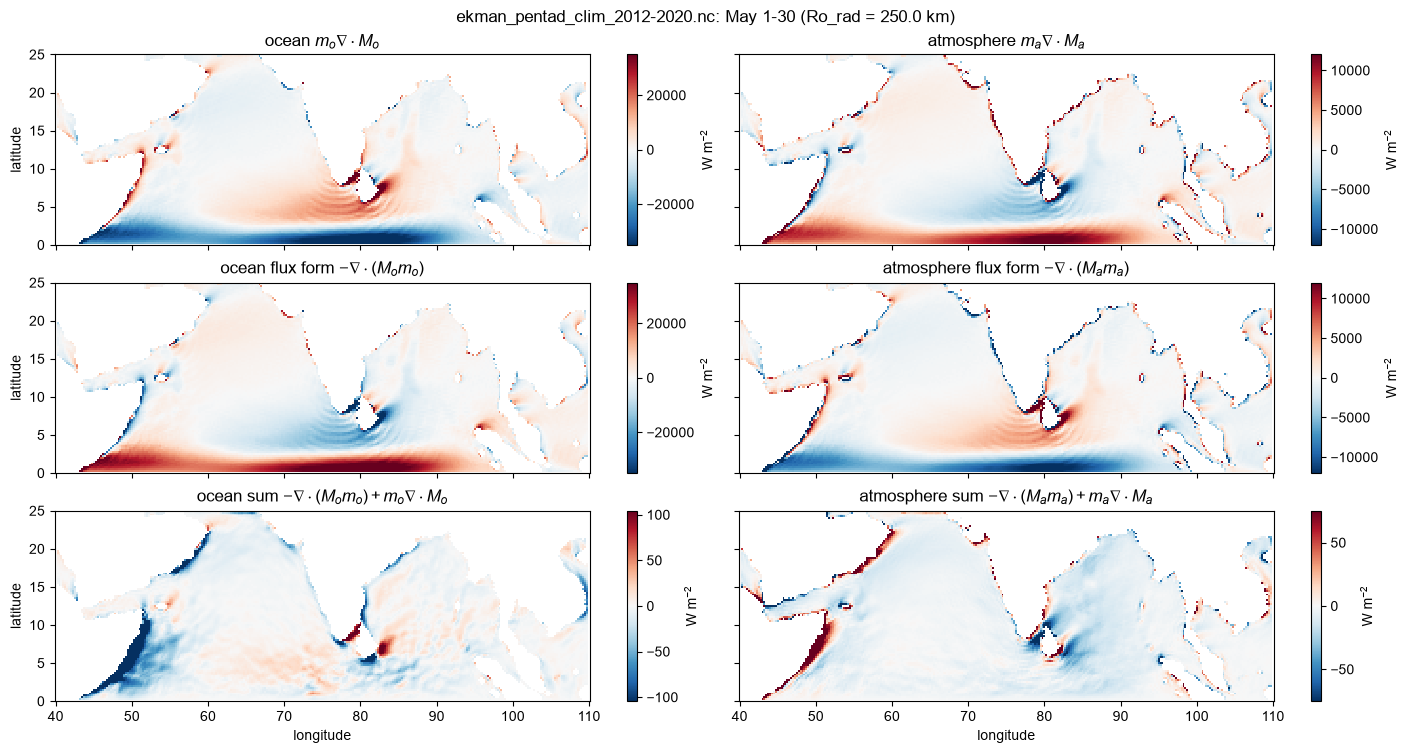

In [3]:
fig3, axs3, meshes3, cbars3 = plot_panels(f, [ # color limits: ±symlim of each map
    panel(f.sdiv_o, raw"ocean $h_o \nabla \cdot M_o$", flux_units),
    panel(f.sdiv_a, raw"atmosphere $h_a \nabla \cdot M_a$", flux_units),
    panel(f.flux_o, raw"ocean flux form $-\nabla \cdot (M_o h_o)$", flux_units),
    panel(f.flux_a, raw"atmosphere flux form $-\nabla \cdot (M_a h_a)$", flux_units),
    panel(f.flux_o .+ f.sdiv_o, raw"ocean sum $-\nabla \cdot (M_o h_o) + h_o \nabla \cdot M_o$", flux_units),
    panel(f.flux_a .+ f.sdiv_a, raw"atmosphere sum $-\nabla \cdot (M_a h_a) + h_a \nabla \cdot M_a$", flux_units)];
    suptitle=figtitle(f), ylim=latlim);
# fig3.savefig("ekman_sdiv_flux_$(period_tag(f.dimval)).png"; bbox_inches="tight")